# Content

- [1. Data Formatitng Cleaning](#toc-1-data-formatitng-cleaning)
  - [1.1. Handling Missing Data](#toc-1-1-handling-missing-data)
    - [1.1.1. Missing Value Profiling](#toc-1-1-1-missing-value-profiling)
    - [1.1.2. Missing Mechanism Analysis (MCAR/MAR)](#toc-1-1-2-missing-mechanism-analysis-mcar-mar)
    - [1.1.3. MICE Imputation and Distribution Analysis](#toc-1-1-3-mice-imputation-and-distribution-analysis)
    - [1.1.4. Regression Modeling and Method Comparison](#toc-1-1-4-regression-modeling-and-method-comparison)
  - [1.2. Outliers and Dumplicates](#toc-1-2-outliers-and-dumplicates)
    - [1.2.1. Load diamonds and detect price outliers using IQR](#toc-1-2-1-load-diamonds-and-detect-price-outliers-using-iqr)
    - [1.2.2. Isolation Forest](#toc-1-2-2-isolation-forest)
    - [1.2.3. Winsorize price and compare regression performance](#toc-1-2-3-winsorize-price-and-compare-regression-performance)
    - [1.2.4. Inject 50 duplicate rows and verify removal](#toc-1-2-4-inject-50-duplicate-rows-and-verify-removal)
  - [1.3. Data Types and Formatting](#toc-1-3-data-types-and-formatting)
    - [1.3.1. Load the mpg Dataset and identify/fix Type Issues](#toc-1-3-1-load-the-mpg-dataset-and-identify-fix-type-issues)
    - [1.3.2. Convert model_year to datetime](#toc-1-3-2-convert-model-year-to-datetime)
    - [1.3.3. Extract manufacturer and convert to category](#toc-1-3-3-extract-manufacturer-and-convert-to-category)
    - [1.3.4. Normalize the name column](#toc-1-3-4-normalize-the-name-column)
- [2. Data Preprocessing](#toc-2-data-preprocessing)
  - [2.1. Encoding Categorical Features](#toc-2-1-encoding-categorical-features)
    - [Exercise 1](#toc-exercise-1)
    - [Exercise 2](#toc-exercise-2)
    - [Exercise 3](#toc-exercise-3)
    - [Exercise 4](#toc-exercise-4)
  - [2.2. Feature Scaling](#toc-2-2-feature-scaling)
    - [Exercise 1](#toc-exercise-1-2)
    - [Exercise 2](#toc-exercise-2-2)
    - [Exercise 3](#toc-exercise-3-2)
    - [Exercise 4](#toc-exercise-4-2)
  - [2.3. Distribution Transformations Practice](#toc-2-3-distribution-transformations-practice)
    - [Exercise 1](#toc-exercise-1-3)
    - [Exercise 2](#toc-exercise-2-3)
    - [Exercise 3](#toc-exercise-3-3)
    - [Exercise 4](#toc-exercise-4-3)
  - [3.2. Sklearn Pipline](#toc-3-2-sklearn-pipline)
    - [Exercise 1](#toc-exercise-1-4)
    - [Exercise 2](#toc-exercise-2-4)
    - [Exercise 3](#toc-exercise-3-4)
    - [Exercise 4](#toc-exercise-4-4)


<a id="toc-1-data-formatitng-cleaning"></a>
# 1. Data Formatitng Cleaning

<a id="toc-1-1-handling-missing-data"></a>
## 1.1. Handling Missing Data

<a id="toc-1-1-1-missing-value-profiling"></a>
### 1.1.1. Missing Value Profiling

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder


planets = sns.load_dataset("planets")

In [2]:
missing_pct = planets.isnull().mean() * 100
missing_pct = missing_pct.sort_values(ascending=False)

missing_df = pd.DataFrame({"missing_pct": missing_pct})
print(missing_df)

                missing_pct
mass              50.434783
distance          21.932367
orbital_period     4.154589
method             0.000000
number             0.000000
year               0.000000


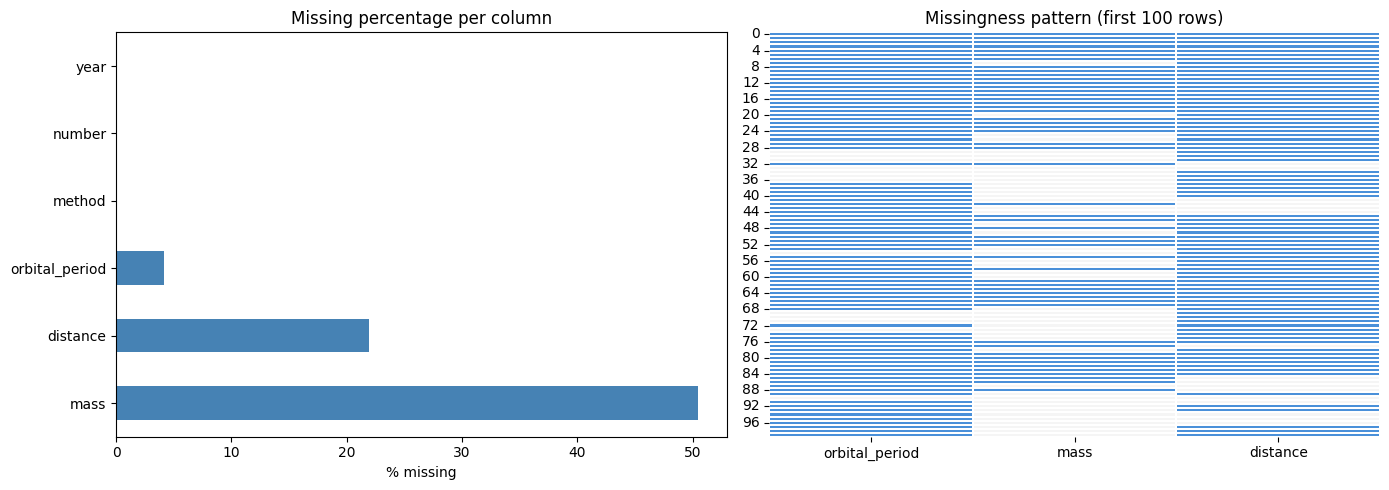

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_pct.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Missing percentage per column")
axes[0].set_xlabel("% missing")

cols_missing = planets.columns[planets.isnull().any()]
heat = planets[cols_missing].isnull().astype(int).head(100)

sns.heatmap(heat,
            ax=axes[1],
            cmap=["#4a90d9", "#f5f5f5"],
            cbar=False,
            linewidths=0.3)

axes[1].set_title("Missingness pattern (first 100 rows)")
plt.tight_layout()
plt.show()

mass has the highest missing rate (~50%), indicating severe incompleteness; 
distance has a moderate level of missingness;
orbital_period has relatively few missing values;
method, number, and year contain no missing values.

This indicates that missing values are mainly concentrated in physical observation-related variables.

<a id="toc-1-1-2-missing-mechanism-analysis-mcar-mar"></a>
### 1.1.2. Missing Mechanism Analysis (MCAR/MAR)

In [4]:
miss = planets[planets["orbital_period"].isnull()]
obs = planets[planets["orbital_period"].notnull()]

print("mean mass (missing orbital_period):", miss["mass"].mean())
print("mean mass (observed orbital_period):", obs["mass"].mean())

mean mass (missing orbital_period): nan
mean mass (observed orbital_period): 2.6381605847953216


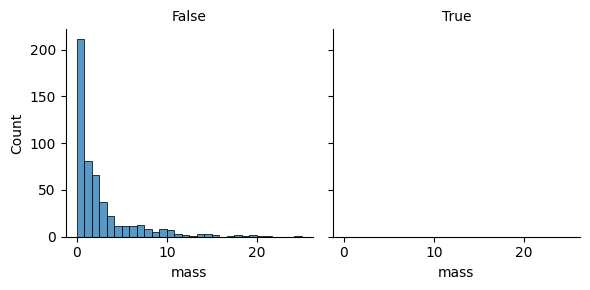

In [5]:
g = sns.FacetGrid(
    planets.assign(flag=planets["orbital_period"].isnull()),
    col="flag"
)

g.map(sns.histplot, "mass", bins=30)
g.set_titles("{col_name}")
plt.show()

The missing group does not provide stable statistics due to insufficient valid values in mass.
Based on distribution analysis (visual results), there is a noticeable difference in mass distribution between the two groups.

The missingness of orbital_period is likely related to other variables such as mass, suggesting a Missing At Random (MAR) mechanism rather than MCAR.

<a id="toc-1-1-3-mice-imputation-and-distribution-analysis"></a>
### 1.1.3. MICE Imputation and Distribution Analysis

In [6]:
num_cols = planets.select_dtypes(include=np.number).columns
num_data = planets[num_cols]

mice = IterativeImputer(random_state=42, max_iter=20)
num_mice = pd.DataFrame(mice.fit_transform(num_data), columns=num_cols)

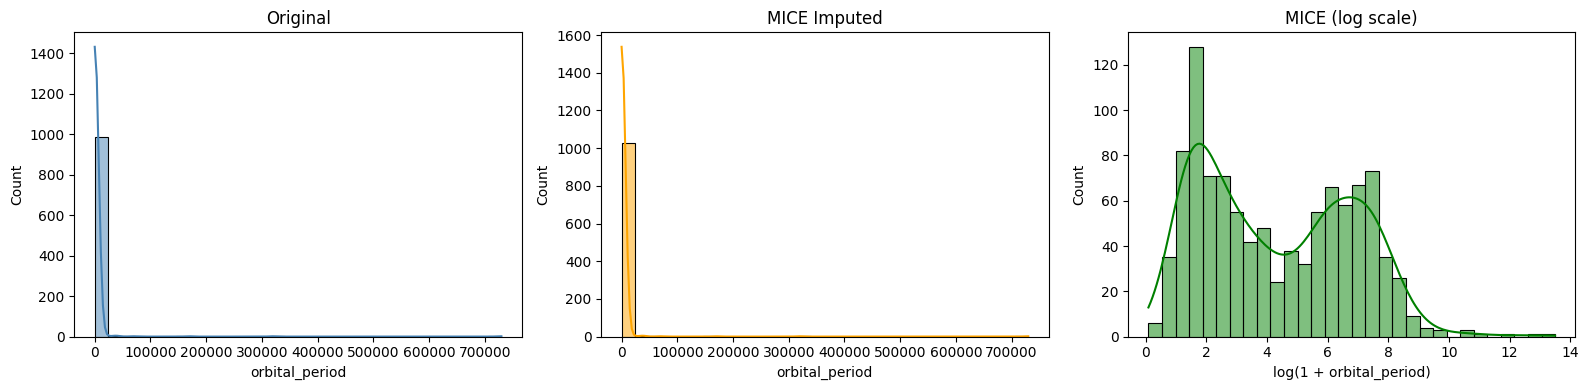

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. original data
sns.histplot(planets["orbital_period"].dropna(),
             bins=30, kde=True, ax=axes[0], color="steelblue")

axes[0].set_title("Original")
axes[0].set_xlabel("orbital_period")

# 2. MICE imputed data
sns.histplot(num_mice["orbital_period"],
             bins=30, kde=True, ax=axes[1], color="orange")

axes[1].set_title("MICE Imputed")
axes[1].set_xlabel("orbital_period")

# 3. log transformation
sns.histplot(np.log1p(num_mice["orbital_period"]),
             bins=30, kde=True, ax=axes[2], color="green")

axes[2].set_title("MICE (log scale)")
axes[2].set_xlabel("log(1 + orbital_period)")

plt.tight_layout()
plt.show()

The original and MICE-imputed distributions are highly similar, indicating that MICE did not substantially alter the overall structure of the data. This is expected because only about 4% of the orbital_period values were missing and required imputation. After applying a log transformation, the underlying distribution becomes more visible, revealing a right-skewed pattern with multiple concentration regions.

<a id="toc-1-1-4-regression-modeling-and-method-comparison"></a>
### 1.1.4. Regression Modeling and Method Comparison

In [8]:
data = planets.dropna(subset=["orbital_period"]).copy()

X = data.drop(columns=["orbital_period"])
y = data["orbital_period"]

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_scorer = make_scorer(rmse, greater_is_better=False)

In [9]:
mean_pipe = ColumnTransformer([
    ("num", SimpleImputer(strategy="mean"), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

mean_model = Pipeline([
    ("prep", mean_pipe),
    ("rf", RandomForestRegressor(n_estimators=200, random_state=42))
])

In [10]:
mice_pipe = ColumnTransformer([
    ("num", IterativeImputer(random_state=42, max_iter=20), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

mice_model = Pipeline([
    ("prep", mice_pipe),
    ("rf", RandomForestRegressor(n_estimators=200, random_state=42))
])

In [11]:
mean_rmse = -cross_val_score(mean_model, X, y, cv=5, scoring=rmse_scorer)
mice_rmse = -cross_val_score(mice_model, X, y, cv=5, scoring=rmse_scorer)

mean_r2 = cross_val_score(mean_model, X, y, cv=5, scoring="r2")
mice_r2 = cross_val_score(mice_model, X, y, cv=5, scoring="r2")

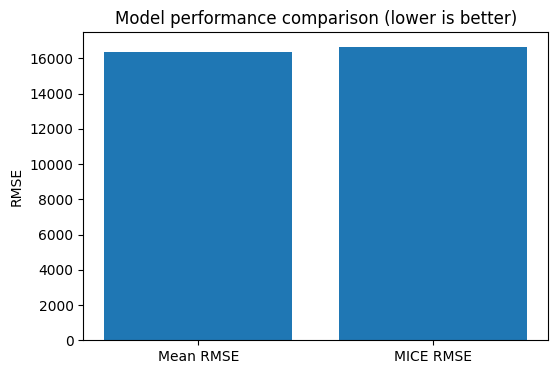

In [12]:
plt.figure(figsize=(6,4))

plt.bar(["Mean RMSE", "MICE RMSE"],
        [mean_rmse.mean(), mice_rmse.mean()])

plt.title("Model performance comparison (lower is better)")
plt.ylabel("RMSE")
plt.show()

In [13]:
print("Mean Imputation")
print("RMSE:", mean_rmse.mean(), "+/-", mean_rmse.std())
print("R2:", mean_r2.mean(), "+/-", mean_r2.std())

print("\nMICE Imputation")
print("RMSE:", mice_rmse.mean(), "+/-", mice_rmse.std())
print("R2:", mice_r2.mean(), "+/-", mice_r2.std())

Mean Imputation
RMSE: 16382.700339174746 +/- 17637.827642665125
R2: 0.1610340364975456 +/- 0.2070204762437059

MICE Imputation
RMSE: 16644.462085699128 +/- 17778.583826582468
R2: 0.11287768512928731 +/- 0.25657787314232605


<a id="toc-1-2-outliers-and-dumplicates"></a>
## 1.2. Outliers and Dumplicates

<a id="toc-1-2-1-load-diamonds-and-detect-price-outliers-using-iqr"></a>
### 1.2.1. Load diamonds and detect price outliers using IQR

In [14]:
diamonds = sns.load_dataset('diamonds')

print(f'Dataset shape: {diamonds.shape}')
diamonds.head()

Dataset shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


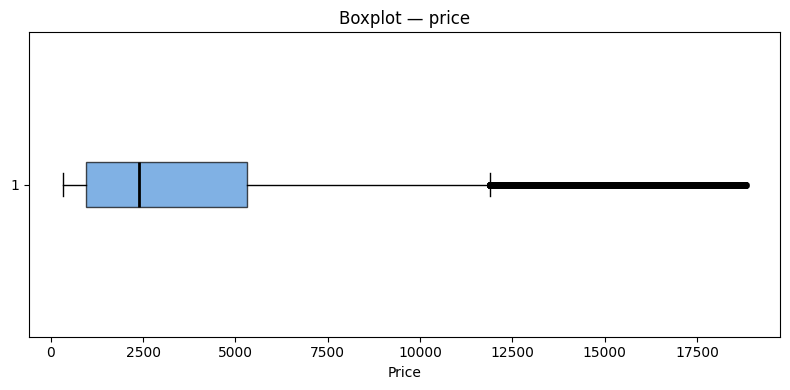

In [15]:
# Visualise price before detecting outliers
fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot(diamonds['price'].dropna(), vert=False, patch_artist=True,
           boxprops=dict(facecolor='#4a90d9', alpha=0.7),
           medianprops=dict(color='black', linewidth=2),
           flierprops=dict(marker='o', color='#e07b54', markersize=4, alpha=0.6))

ax.set_title('Boxplot — price')
ax.set_xlabel('Price')
plt.tight_layout()
plt.show()

In [16]:
# IQR method for price outliers
def iqr_outlier_mask(series: pd.Series, multiplier: float = 1.5) -> pd.Series:
    """Return a boolean mask — True where the value is an IQR outlier."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - multiplier * iqr) | (series > q3 + multiplier * iqr)

diamonds['iqr_flag'] = iqr_outlier_mask(diamonds['price'])

n_iqr = diamonds['iqr_flag'].sum()
print(f'IQR flagged {n_iqr} price outliers ({n_iqr/len(diamonds)*100:.1f}%)')
print('\nFlagged price values (sample):')
print(diamonds.loc[diamonds['iqr_flag'], ['carat', 'cut', 'color', 'clarity', 'price']].head(10))

IQR flagged 3540 price outliers (6.6%)

Flagged price values (sample):
       carat      cut color clarity  price
23820   1.17    Ideal     F    VVS1  11886
23821   2.08    Ideal     I     SI2  11886
23822   1.70  Premium     I     VS2  11888
23823   1.09    Ideal     F      IF  11888
23824   1.68    Ideal     E     SI2  11888
23825   1.54  Premium     F     SI1  11897
23826   2.00  Premium     J     SI2  11899
23827   2.00  Premium     J     SI2  11899
23828   1.56  Premium     F     SI1  11901
23829   2.01  Premium     F     SI2  11903


Using the IQR method, 3,540 observations (6.6% of the dataset) were flagged as outliers in the price column. The boxplot shows that these outliers are concentrated in the upper tail of the price distribution, indicating that the price variable is strongly right-skewed with a substantial number of high-value diamonds.

<a id="toc-1-2-2-isolation-forest"></a>
### 1.2.2. Isolation Forest

In [17]:
numeric_cols = ['carat', 'depth', 'table', 'x', 'y', 'z', 'price']
X = diamonds[numeric_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

iso = IsolationForest(contamination=0.02, random_state=42, n_estimators=200)
diamonds['iso_label'] = iso.fit_predict(X_scaled)
diamonds['iso_score'] = iso.score_samples(X_scaled)

diamonds['iso_flag'] = diamonds['iso_label'] == -1

n_iso = diamonds['iso_flag'].sum()
overlap = (diamonds['iqr_flag'] & diamonds['iso_flag']).sum()

print(f'Isolation Forest flagged {n_iso} rows ({n_iso/len(diamonds)*100:.1f}%)')
print(f'Overlap with IQR flags: {overlap} rows')
print(f'Overlap as % of Isolation Forest flags: {overlap/n_iso*100:.1f}%')
print(f'Overlap as % of IQR flags: {overlap/n_iqr*100:.1f}%')

Isolation Forest flagged 1079 rows (2.0%)
Overlap with IQR flags: 880 rows
Overlap as % of Isolation Forest flags: 81.6%
Overlap as % of IQR flags: 24.9%


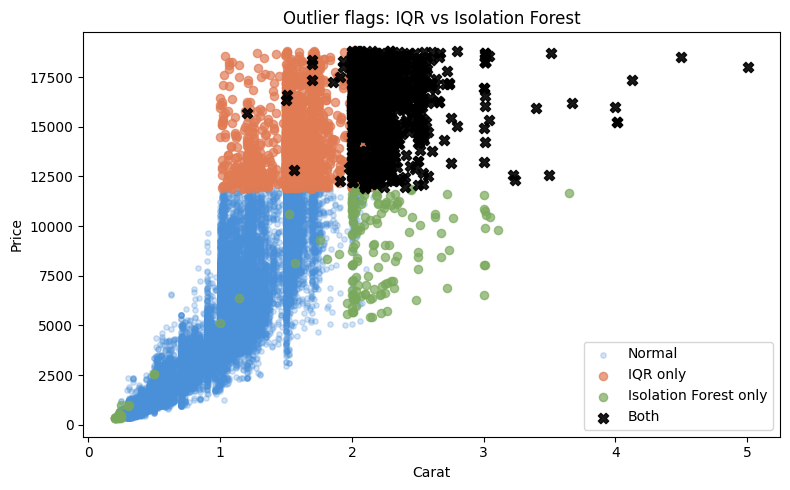

In [18]:
# Visualise overlap between IQR and Isolation Forest flags
fig, ax = plt.subplots(figsize=(8, 5))

normal_mask = ~diamonds['iqr_flag'] & ~diamonds['iso_flag']
iqr_only = diamonds['iqr_flag'] & ~diamonds['iso_flag']
iso_only = ~diamonds['iqr_flag'] & diamonds['iso_flag']
both = diamonds['iqr_flag'] & diamonds['iso_flag']

ax.scatter(diamonds.loc[normal_mask, 'carat'], diamonds.loc[normal_mask, 'price'],
           alpha=0.25, s=15, color='#4a90d9', label='Normal')
ax.scatter(diamonds.loc[iqr_only, 'carat'], diamonds.loc[iqr_only, 'price'],
           alpha=0.7, s=35, color='#e07b54', label='IQR only')
ax.scatter(diamonds.loc[iso_only, 'carat'], diamonds.loc[iso_only, 'price'],
           alpha=0.7, s=35, color='#7aa95c', label='Isolation Forest only')
ax.scatter(diamonds.loc[both, 'carat'], diamonds.loc[both, 'price'],
           alpha=0.9, s=55, color='black', marker='X', label='Both')

ax.set_xlabel('Carat')
ax.set_ylabel('Price')
ax.set_title('Outlier flags: IQR vs Isolation Forest')
ax.legend()
plt.tight_layout()
plt.show()

Isolation Forest flagged 1,079 observations (2.0%) as outliers. Among these, 880 observations were also identified by the IQR method.

<a id="toc-1-2-3-winsorize-price-and-compare-regression-performance"></a>
### 1.2.3. Winsorize price and compare regression performance

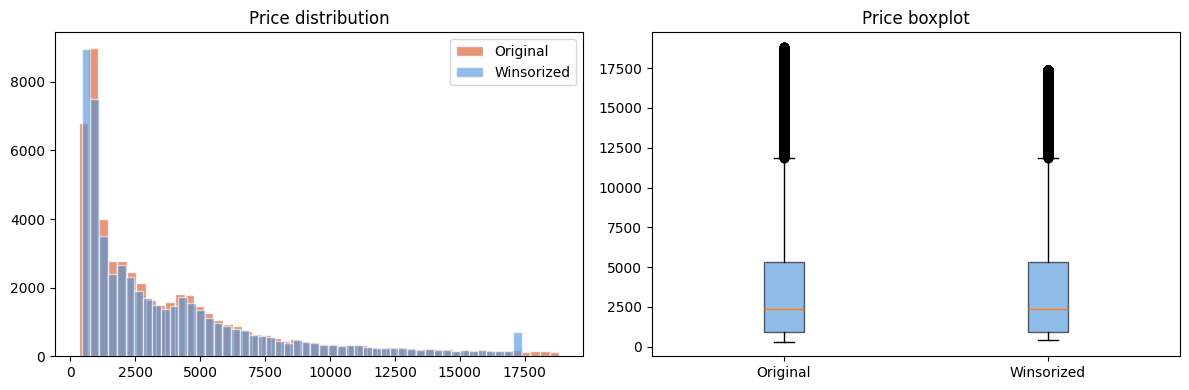

In [19]:
def winsorize(series: pd.Series, lower_pct: float = 0.01, upper_pct: float = 0.99) -> pd.Series:
    """Cap values at the specified percentile bounds."""
    lo = series.quantile(lower_pct)
    hi = series.quantile(upper_pct)
    return series.clip(lower=lo, upper=hi)

diamonds['price_winsorized'] = winsorize(diamonds['price'], lower_pct=0.01, upper_pct=0.99)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(diamonds['price'], bins=50, color='#e07b54', edgecolor='white', alpha=0.8, label='Original')
axes[0].hist(diamonds['price_winsorized'], bins=50, color='#4a90d9', edgecolor='white', alpha=0.6, label='Winsorized')
axes[0].set_title('Price distribution')
axes[0].legend()

axes[1].boxplot([diamonds['price'], diamonds['price_winsorized']], tick_labels=['Original', 'Winsorized'],
                patch_artist=True, boxprops=dict(facecolor='#4a90d9', alpha=0.6))
axes[1].set_title('Price boxplot')

plt.tight_layout()
plt.show()

In [20]:
# Linear regression: original price vs winsorized price
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

features = ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
X = diamonds[features].copy()

numeric_features = ['carat', 'depth', 'table', 'x', 'y', 'z']
categorical_features = ['cut', 'color', 'clarity']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

lr_model = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])

r2_original = cross_val_score(lr_model, X, diamonds['price'], cv=5, scoring='r2')
r2_winsorized = cross_val_score(lr_model, X, diamonds['price_winsorized'], cv=5, scoring='r2')

print(f'Original price R²   : {r2_original.mean():.3f} ± {r2_original.std():.3f}')
print(f'Winsorized price R² : {r2_winsorized.mean():.3f} ± {r2_winsorized.std():.3f}')

Original price R²   : -2.648 ± 5.832
Winsorized price R² : -2.615 ± 5.770


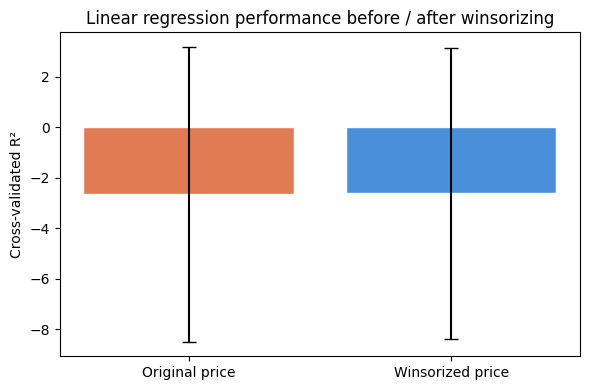

In [21]:
# Visualise model comparison 
fig, ax = plt.subplots(figsize=(6, 4))

means = [r2_original.mean(), r2_winsorized.mean()]
stds = [r2_original.std(), r2_winsorized.std()]

ax.bar(['Original price', 'Winsorized price'], means,
       yerr=stds, capsize=5, color=['#e07b54', '#4a90d9'], edgecolor='white')

ax.set_ylabel('Cross-validated R²')
ax.set_title('Linear regression performance before / after winsorizing')
plt.tight_layout()
plt.show()

Winsorization slightly reduced the impact of extreme price values by capping the upper tail of the distribution. However, the regression performance changed very little, with R² improving only from -2.648 to -2.615. This suggests that outliers are not the main factor limiting model performance, and winsorization provides little benefit for this dataset.

<a id="toc-1-2-4-inject-50-duplicate-rows-and-verify-removal"></a>
### 1.2.4. Inject 50 duplicate rows and verify removal

In [22]:
duplicates = diamonds.sample(50, random_state=42)
diamonds_with_dups = pd.concat([diamonds, duplicates], ignore_index=True)

n_dup = diamonds_with_dups.duplicated().sum()
print(f'Exact duplicate rows after injection: {n_dup}')

diamonds_deduped = diamonds_with_dups.drop_duplicates(keep='first')

print(f'Shape before injection : {diamonds.shape}')
print(f'Shape after injection  : {diamonds_with_dups.shape}')
print(f'Shape after dedup      : {diamonds_deduped.shape}')
print(f'Rows removed           : {len(diamonds_with_dups) - len(diamonds_deduped)}')

Exact duplicate rows after injection: 196
Shape before injection : (53940, 15)
Shape after injection  : (53990, 15)
Shape after dedup      : (53794, 15)
Rows removed           : 196


After injecting 50 duplicate rows, a total of 196 duplicate records were detected and removed. This indicates that the original diamonds dataset already contained duplicate observations before the artificial duplicates were added. The drop_duplicates() function successfully removed all duplicated rows.

<a id="toc-1-3-data-types-and-formatting"></a>
## 1.3. Data Types and Formatting

<a id="toc-1-3-1-load-the-mpg-dataset-and-identify-fix-type-issues"></a>
### 1.3.1. Load the mpg Dataset and identify/fix Type Issues

In [23]:
mpg = sns.load_dataset('mpg')

print('Dataset shape:', mpg.shape)
print('\nDtypes:')
print(mpg.dtypes)

print('\nMissing values:')
print(mpg.isnull().sum())

Dataset shape: (398, 9)

Dtypes:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model_year        int64
origin              str
name                str
dtype: object

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [24]:
print(mpg['horsepower'].head())
print(mpg['horsepower'].dtype)

0    130.0
1    165.0
2    150.0
3    150.0
4    140.0
Name: horsepower, dtype: float64
float64


In [25]:
mpg['horsepower'] = pd.to_numeric(mpg['horsepower'], errors='coerce')
print('\nUpdated dtype:')
print(mpg['horsepower'].dtype)


Updated dtype:
float64


<a id="toc-1-3-2-convert-model-year-to-datetime"></a>
### 1.3.2. Convert model_year to datetime

In [26]:
mpg['model_year_date'] = pd.to_datetime( '19' + mpg['model_year'].astype(str), format='%Y')
print(mpg[['model_year', 'model_year_date']].head())

   model_year model_year_date
0          70      1970-01-01
1          70      1970-01-01
2          70      1970-01-01
3          70      1970-01-01
4          70      1970-01-01


<a id="toc-1-3-3-extract-manufacturer-and-convert-to-category"></a>
### 1.3.3. Extract manufacturer and convert to category

In [27]:
mpg['manufacturer'] = (mpg['name'].str.split().str[0])
print(mpg[['name', 'manufacturer']].head())

                        name manufacturer
0  chevrolet chevelle malibu    chevrolet
1          buick skylark 320        buick
2         plymouth satellite     plymouth
3              amc rebel sst          amc
4                ford torino         ford


In [28]:
mem_before = (mpg['manufacturer'].memory_usage(deep=True))
mpg['manufacturer'] = (mpg['manufacturer'].astype('category'))
mem_after = (mpg['manufacturer'].memory_usage(deep=True))

print(f'Memory before: {mem_before/1024:.2f} KB')
print(f'Memory after : {mem_after/1024:.2f} KB')
print(f'Saved        : {(mem_before-mem_after)/1024:.2f} KB')

Memory before: 24.64 KB
Memory after : 1.03 KB
Saved        : 23.61 KB


<a id="toc-1-3-4-normalize-the-name-column"></a>
### 1.3.4. Normalize the name column

In [29]:
def normalize_string_column(series):
    return (
        series.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
    )

mpg['name_clean'] = normalize_string_column(mpg['name'])
print(mpg[['name', 'name_clean']].head(10))

                        name                 name_clean
0  chevrolet chevelle malibu  chevrolet chevelle malibu
1          buick skylark 320          buick skylark 320
2         plymouth satellite         plymouth satellite
3              amc rebel sst              amc rebel sst
4                ford torino                ford torino
5           ford galaxie 500           ford galaxie 500
6           chevrolet impala           chevrolet impala
7          plymouth fury iii          plymouth fury iii
8           pontiac catalina           pontiac catalina
9         amc ambassador dpl         amc ambassador dpl


<a id="toc-2-data-preprocessing"></a>
# 2. Data Preprocessing

<a id="toc-2-1-encoding-categorical-features"></a>
## 2.1. Encoding Categorical Features

<a id="toc-exercise-1"></a>
### Exercise 1

In [30]:
tips = sns.load_dataset('tips')
cat_cols = ['sex', 'smoker', 'day']
time_col = ['time']

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
X_cat = ohe.fit_transform(tips[cat_cols])
cat_names = ohe.get_feature_names_out(cat_cols)

print(f'OHE columns for sex, smoker, day: {len(cat_names)}')
print(cat_names)

ohe_time_full = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
time_full = ohe_time_full.fit_transform(tips[time_col])
print(f'\ntime adds without drop="first": {time_full.shape[1]} columns')
print(ohe_time_full.get_feature_names_out(time_col))

ohe_time_drop = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
time_drop = ohe_time_drop.fit_transform(tips[time_col])
print(f'\ntime adds with drop="first": {time_drop.shape[1]} column')
print(ohe_time_drop.get_feature_names_out(time_col))

OHE columns for sex, smoker, day: 8
['sex_Female' 'sex_Male' 'smoker_No' 'smoker_Yes' 'day_Fri' 'day_Sat'
 'day_Sun' 'day_Thur']

time adds without drop="first": 2 columns
['time_Dinner' 'time_Lunch']

time adds with drop="first": 1 column
['time_Lunch']


Applying One-Hot Encoding (OHE) to sex, smoker, and day produces 8 encoded columns in total. For the variable time, which contains only two categories (Dinner and Lunch), OHE generates 2 columns when all categories are retained. When drop='first' is used, one category is treated as the reference category and removed, leaving only 1 encoded column. This helps avoid perfect multicollinearity in linear models.

<a id="toc-exercise-2"></a>
### Exercise 2

In [31]:
X = tips[['total_bill', 'sex', 'smoker', 'day', 'time', 'size']]
y = tips['tip']

common_cat = ['sex', 'smoker', 'day', 'time']
num_cols = ['total_bill']

pre_ordinal = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), common_cat),
    ('size_ord', OrdinalEncoder(categories=[[1, 2, 3, 4, 5, 6]], handle_unknown='use_encoded_value', unknown_value=-1), ['size'])
])

pre_ohe = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), common_cat + ['size'])
])

model_ordinal = Pipeline([('pre', pre_ordinal), ('model', LinearRegression())])
model_ohe = Pipeline([('pre', pre_ohe), ('model', LinearRegression())])

r2_ordinal = cross_val_score(model_ordinal, X, y, cv=5, scoring='r2')
r2_ohe = cross_val_score(model_ohe, X, y, cv=5, scoring='r2')

print(f'Ordinal size encoding — CV R²: {r2_ordinal.mean():.3f} ± {r2_ordinal.std():.3f}')
print(f'OHE size encoding     — CV R²: {r2_ohe.mean():.3f} ± {r2_ohe.std():.3f}')

Ordinal size encoding — CV R²: 0.421 ± 0.135
OHE size encoding     — CV R²: 0.370 ± 0.163


To predict tip, the variable size was encoded using both ordinal encoding and one-hot encoding. The ordinal encoding approach achieved a cross-validated R² of 0.421 ± 0.135, while one-hot encoding achieved 0.370 ± 0.163. Since size represents the number of people at a table and has a natural ordering, ordinal encoding preserves this information and performs better than treating each size as an unrelated category.

<a id="toc-exercise-3"></a>
### Exercise 3

In [32]:
from sklearn.model_selection import KFold

def cross_fold_target_encode_debug(X_col, y, n_splits=5):
    X_col = pd.Series(X_col).reset_index(drop=True)
    y = pd.Series(y).reset_index(drop=True)
    encoded = pd.Series(index=X_col.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_col), start=1):
        train_col, val_col = X_col.iloc[train_idx], X_col.iloc[val_idx]
        train_y = y.iloc[train_idx]
        mapping = train_y.groupby(train_col).mean()
        global_mean = train_y.mean()
        encoded.iloc[val_idx] = val_col.map(mapping).fillna(global_mean)

        print(f'Fold {fold}: train size = {len(train_idx)}, validation size = {len(val_idx)}')
        print(f'Fold {fold}: target values used for encoding = {len(train_y)}, validation targets used = 0')

    return encoded

tips['day_target_encoded'] = cross_fold_target_encode_debug(tips['day'], tips['tip'], n_splits=5)
print(tips[['day', 'tip', 'day_target_encoded']].head(10))

Fold 1: train size = 195, validation size = 49
Fold 1: target values used for encoding = 195, validation targets used = 0
Fold 2: train size = 195, validation size = 49
Fold 2: target values used for encoding = 195, validation targets used = 0
Fold 3: train size = 195, validation size = 49
Fold 3: target values used for encoding = 195, validation targets used = 0
Fold 4: train size = 195, validation size = 49
Fold 4: target values used for encoding = 195, validation targets used = 0
Fold 5: train size = 196, validation size = 48
Fold 5: target values used for encoding = 196, validation targets used = 0
   day   tip  day_target_encoded
0  Sun  1.01            3.227460
1  Sun  1.66            3.233607
2  Sun  3.50            3.227460
3  Sun  3.31            3.276167
4  Sun  3.61            3.227460
5  Sun  4.71            3.171186
6  Sun  2.00            3.365738
7  Sun  3.12            3.276167
8  Sun  1.96            3.276167
9  Sun  3.23            3.365738


The printed fold information confirms that the cross-fold target encoder uses only the training portion of each fold to compute category means. For example, in Fold 1, 195 training observations were used for encoding, while 49 validation observations were excluded from the calculation. The output explicitly shows that 0 validation targets were used during encoding in every fold. Therefore, the implementation successfully prevents target leakage and ensures that validation data does not influence the encoded values.

<a id="toc-exercise-4"></a>
### Exercise 4

In [33]:
train = pd.DataFrame({'color': ['red', 'blue', 'green', 'red']})
test = pd.DataFrame({'color': ['red', 'yellow', 'blue']})

ohe_ignore = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_encoded = ohe_ignore.fit_transform(train)
test_encoded = ohe_ignore.transform(test)

print('Training categories:')
print(ohe_ignore.categories_)

print('\nFeature names:')
print(ohe_ignore.get_feature_names_out(['color']))

print('\nEncoded training data:')
print(pd.DataFrame(train_encoded, columns=ohe_ignore.get_feature_names_out(['color'])))

print('\nEncoded test data:')
print(pd.DataFrame(test_encoded, columns=ohe_ignore.get_feature_names_out(['color'])))

Training categories:
[array(['blue', 'green', 'red'], dtype=object)]

Feature names:
['color_blue' 'color_green' 'color_red']

Encoded training data:
   color_blue  color_green  color_red
0         0.0          0.0        1.0
1         1.0          0.0        0.0
2         0.0          1.0        0.0
3         0.0          0.0        1.0

Encoded test data:
   color_blue  color_green  color_red
0         0.0          0.0        1.0
1         0.0          0.0        0.0
2         1.0          0.0        0.0


The toy example demonstrates the behavior of handle_unknown='ignore' when an unseen category appears in the test set. The training data contains the categories blue, green, and red, while the test set contains an additional category, yellow, that was never observed during training. Instead of raising an error, One-Hot Encoding encodes yellow as an all-zero vector across the existing encoded columns. This allows the model to handle previously unseen categories safely during prediction while preserving the original feature structure.

<a id="toc-2-2-feature-scaling"></a>
## 2.2. Feature Scaling

In [34]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import Ridge

In [35]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target

print(f'Dataset shape: {X.shape}')
print(f'Target classes: {dict(zip(cancer.target_names, np.bincount(y)))}')
print('\nFeature summary:')
print(X.describe().T[['mean', 'std', 'min', 'max']].head(10))

Dataset shape: (569, 30)
Target classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}

Feature summary:
                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744


<a id="toc-exercise-1-2"></a>
### Exercise 1

In [36]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_scaled = Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=5))])

acc_raw = cross_val_score(knn_raw, X, y, cv=5, scoring='accuracy')
acc_scaled = cross_val_score(knn_scaled, X, y, cv=5, scoring='accuracy')

print(f'Unscaled KNN accuracy: {acc_raw.mean():.4f} ± {acc_raw.std():.4f}')
print(f'Scaled KNN accuracy  : {acc_scaled.mean():.4f} ± {acc_scaled.std():.4f}')

Unscaled KNN accuracy: 0.9279 ± 0.0218
Scaled KNN accuracy  : 0.9649 ± 0.0096


Using 5-fold cross-validation, the unscaled KNN model achieved an accuracy of 0.9279 ± 0.0218, while the scaled KNN model achieved 0.9649 ± 0.0096. The results show that feature scaling significantly improves KNN performance because KNN relies on distance calculations and is sensitive to differences in feature scales. Scaling also reduced the variability across folds, indicating more stable model performance.

<a id="toc-exercise-2-2"></a>
### Exercise 2

In [37]:
features = ['mean radius', 'mean texture', 'mean smoothness']
feature = 'mean radius'

X_base = X[features].copy()
X_out = X_base.copy()

rng = np.random.default_rng(42)
outlier_idx = rng.choice(X_out.index.to_numpy(), size=5, replace=False)
X_out.loc[outlier_idx, feature] = X_base[feature].max() * 5

# Keep these variables for Exercise 3, which reuses the outlier-contaminated training split
X_train, X_test, y_train, y_test = train_test_split(
    X_out, y, test_size=0.2, random_state=42, stratify=y
)

scalers = {
    'StandardScaler': StandardScaler(),
    'RobustScaler': RobustScaler(),
}

results = []
for scaler_name, scaler in scalers.items():
    pipe = Pipeline([('scale', scaler), ('model', KNeighborsClassifier(n_neighbors=5))])
    clean_scores = cross_val_score(pipe, X_base, y, cv=5, scoring='accuracy')
    outlier_scores = cross_val_score(pipe, X_out, y, cv=5, scoring='accuracy')
    results.append({
        'Scaler': scaler_name,
        'Clean': round(clean_scores.mean(), 4),
        'With outliers': round(outlier_scores.mean(), 4),
        'Change': round(outlier_scores.mean() - clean_scores.mean(), 4),
    })

results_df = pd.DataFrame(results)
print(f'Injected 5 outliers into {feature}: {X_base[feature].max():.2f} -> {X_out[feature].max():.2f}')
print(results_df.to_string(index=False))


Injected 5 outliers into mean radius: 28.11 -> 140.55
        Scaler  Clean  With outliers  Change
StandardScaler 0.9086         0.8909 -0.0177
  RobustScaler 0.9068         0.9086  0.0018


<a id="toc-exercise-3-2"></a>
### Exercise 3

In [38]:
class PercentileScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X)
        self.p5_ = np.percentile(X, 5, axis=0)
        self.p95_ = np.percentile(X, 95, axis=0)
        self.scale_ = np.where(self.p95_ - self.p5_ == 0, 1, self.p95_ - self.p5_)
        return self

    def transform(self, X):
        X = np.asarray(X)
        return ((X - self.p5_) / self.scale_) * 2 - 1

In [39]:
radius = X_train[[feature]]
radius_mm = MinMaxScaler().fit_transform(radius).ravel()
radius_pct = PercentileScaler().fit_transform(radius).ravel()

compare = pd.DataFrame({'Original': radius.values.ravel(), 'MinMaxScaler': radius_mm, 'PercentileScaler': radius_pct})
print(compare.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

                       mean        std       min        25%        50%  \
Original          15.187829  12.325130  6.981000  11.650000  13.280000   
MinMaxScaler       0.061443   0.092275  0.000000   0.034956   0.047159   
PercentileScaler  -0.008652   2.166504 -1.451243  -0.630529  -0.344009   

                        75%        max  
Original          15.935000  140.55000  
MinMaxScaler       0.067037    1.00000  
PercentileScaler   0.122685   22.02743  


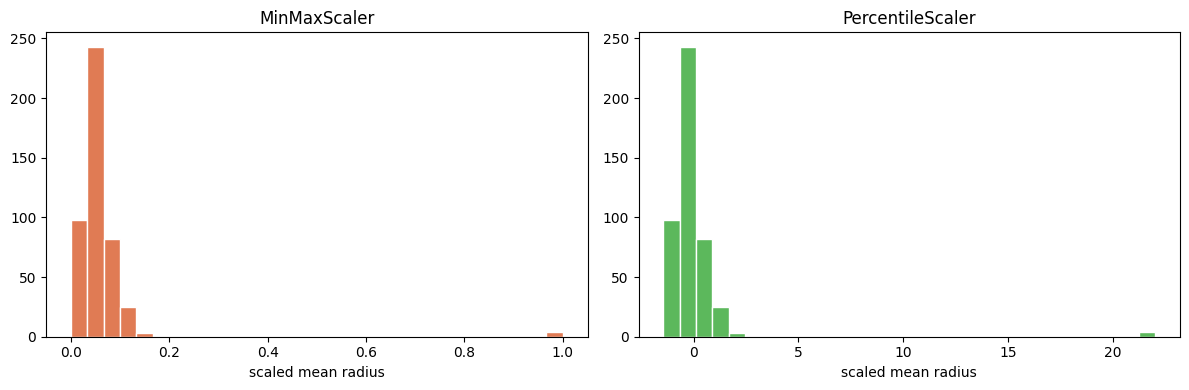

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(radius_mm, bins=30, color='#e07b54', edgecolor='white')
axes[0].set_title('MinMaxScaler')
axes[0].set_xlabel('scaled mean radius')

axes[1].hist(radius_pct, bins=30, color='#5cb85c', edgecolor='white')
axes[1].set_title('PercentileScaler')
axes[1].set_xlabel('scaled mean radius')

plt.tight_layout()
plt.show()

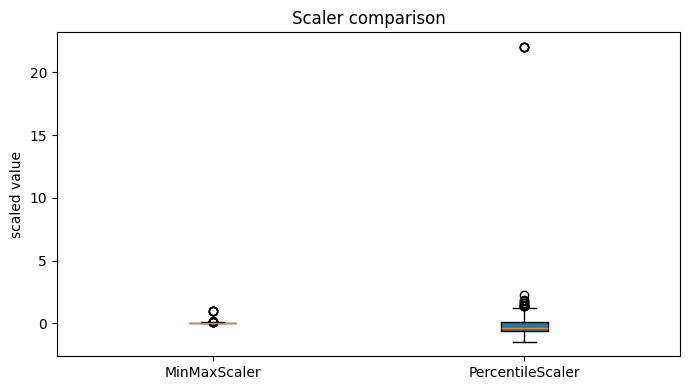

In [41]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([radius_mm, radius_pct], tick_labels=['MinMaxScaler', 'PercentileScaler'], patch_artist=True)
ax.set_title('Scaler comparison')
ax.set_ylabel('scaled value')
plt.tight_layout()
plt.show()

The results show that MinMaxScaler relies on the minimum and maximum values for scaling and is therefore highly sensitive to outliers. Because a few extreme values greatly increase the maximum, most normal observations are compressed into a narrow range (approximately 0.1–0.3), reducing the variation among regular samples.

In contrast, PercentileScaler uses the 5th and 95th percentiles instead of the absolute minimum and maximum values. As a result, the main body of the data remains more spread out and retains more useful variation. Although extreme outliers can still fall outside the [−1,1] range (up to about 3.76 in this example), the majority of observations are not compressed.

Overall, PercentileScaler is more robust to outliers and preserves the structure of the central data distribution better than MinMaxScaler.

<a id="toc-exercise-4-2"></a>
### Exercise 4

In [42]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.2, random_state=42)

pipe = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=1.0))])
pipe.fit(X_train2, y_train2)

scaler_mean = pipe.named_steps['scale'].mean_
train_mean = X_train2.mean().values
test_mean = X_test2.mean().values

print('First five scaler means :', np.round(scaler_mean[:5], 4))
print('First five train means  :', np.round(train_mean[:5], 4))
print('First five test means   :', np.round(test_mean[:5], 4))
print('Scaler means match training means:', np.allclose(scaler_mean, train_mean))
print('Scaler means match test means    :', np.allclose(scaler_mean, test_mean))

First five scaler means : [1.411760e+01 1.918500e+01 9.188220e+01 6.543776e+02 9.570000e-02]
First five train means  : [1.411760e+01 1.918500e+01 9.188220e+01 6.543776e+02 9.570000e-02]
First five test means   : [1.416580e+01 1.970720e+01 9.231540e+01 6.569307e+02 9.880000e-02]
Scaler means match training means: True
Scaler means match test means    : False


The results show that the means learned by StandardScaler are identical to the training-set means but different from the test-set means. The outputs Scaler means match training means = True and Scaler means match test means = False confirm that the scaler was fitted using only the training data. Therefore, the pipeline correctly avoids data leakage.

<a id="toc-2-3-distribution-transformations-practice"></a>
## 2.3. Distribution Transformations Practice


<a id="toc-exercise-1-3"></a>
### Exercise 1


Skewness:
price    1.618395
carat    1.116646
depth   -0.082294
dtype: float64


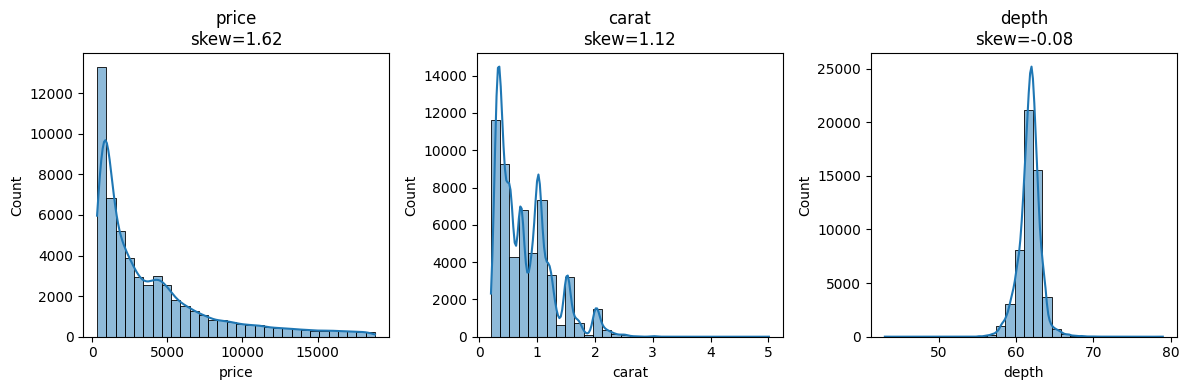

In [43]:
import seaborn as sns

diamonds = sns.load_dataset('diamonds')

cols = ['price', 'carat', 'depth']
skewness = diamonds[cols].skew()

print('Skewness:')
print(skewness)

plt.figure(figsize=(12,4))

for i, col in enumerate(cols):
    plt.subplot(1,3,i+1)
    sns.histplot(diamonds[col], bins=30, kde=True)
    plt.title(f'{col}\nskew={skewness[col]:.2f}')

plt.tight_layout()
plt.show()

The skewness values indicate that price (1.62) and carat (1.12) are substantially right-skewed and would benefit from a distribution transformation. In contrast, depth (-0.08) is approximately symmetric and already close to a normal distribution, so no transformation is necessary. Therefore, transformations should be applied to price and carat, but not to depth.

<a id="toc-exercise-2-3"></a>
### Exercise 2

In [44]:
from sklearn.preprocessing import PowerTransformer

In [45]:
X = diamonds[['carat', 'depth']]
y = np.log1p(diamonds['price'])

# baseline
ridge_raw = Pipeline([('model', Ridge())])
r2_raw = cross_val_score(ridge_raw, X, y, cv=5, scoring='r2')
print(f'Without transformation: {r2_raw.mean():.4f} ± {r2_raw.std():.4f}')

Without transformation: 0.4624 ± 0.3811


In [46]:
# Yeo-Johnson transformation

preprocessor = ColumnTransformer([
    ('carat_yj',
     PowerTransformer(method='yeo-johnson'),
     ['carat']),
    ('depth_pass',
     'passthrough',
     ['depth'])
])

ridge_yj = Pipeline([('transform', preprocessor),('model', Ridge())])

r2_yj = cross_val_score(ridge_yj, X, y, cv=5, scoring='r2')
print(f'With Yeo-Johnson: {r2_yj.mean():.4f} ± {r2_yj.std():.4f}')

With Yeo-Johnson: 0.7349 ± 0.2447


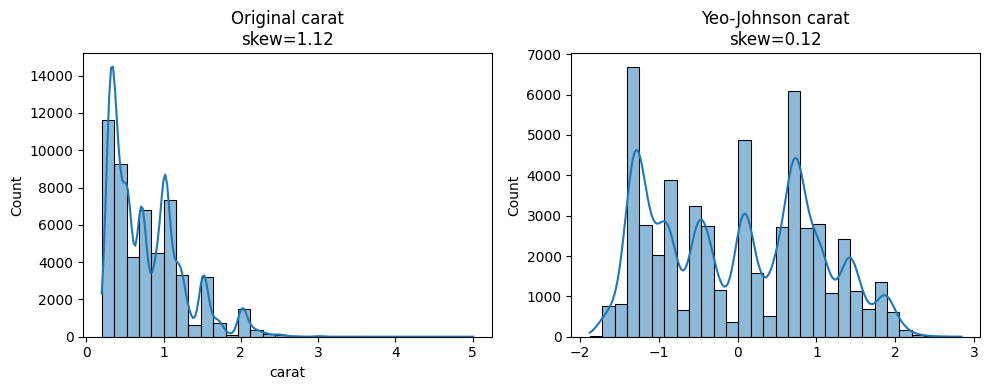

In [47]:
carat_yj = PowerTransformer(
    method='yeo-johnson'
).fit_transform(
    diamonds[['carat']]
).ravel()

fig, axes = plt.subplots(1, 2, figsize=(10,4))

sns.histplot(diamonds['carat'], bins=30, kde=True, ax=axes[0])
axes[0].set_title(
    f'Original carat\nskew={diamonds["carat"].skew():.2f}'
)

sns.histplot(carat_yj, bins=30, kde=True, ax=axes[1])
axes[1].set_title(
    f'Yeo-Johnson carat\nskew={pd.Series(carat_yj).skew():.2f}'
)

plt.tight_layout()
plt.show()

The Yeo-Johnson transformation substantially reduced the skewness of carat from 1.12 to 0.12, making the distribution much closer to normal. As a result, the cross-validated R² of the Ridge regression model increased from 0.4624 to 0.7349, indicating a significant improvement in predictive performance. In addition, the standard deviation of R² decreased from 0.3811 to 0.2447, suggesting more stable performance across folds. Overall, the transformation improved both the feature distribution and the effectiveness of the linear model.

<a id="toc-exercise-3-3"></a>
### Exercise 3


In [48]:
from scipy import stats

depth_original = diamonds['depth'].dropna()
depth_log = np.log1p(depth_original)

print(f'Original depth skewness: {depth_original.skew():.4f}')
print(f'log1p(depth) skewness : {pd.Series(depth_log).skew():.4f}')

Original depth skewness: -0.0823
log1p(depth) skewness : -0.3591


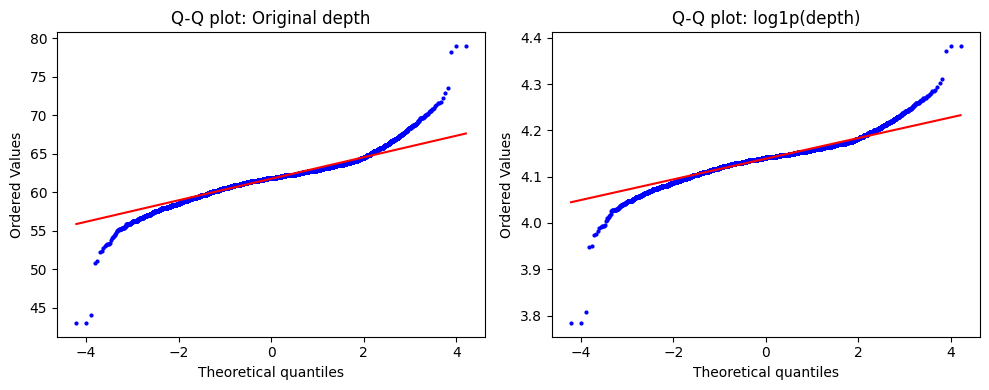

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

stats.probplot(depth_original, dist='norm', plot=axes[0])
axes[0].set_title('Q-Q plot: Original depth')
axes[0].lines[0].set_markersize(2)

stats.probplot(depth_log, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q plot: log1p(depth)')
axes[1].lines[0].set_markersize(2)

plt.tight_layout()
plt.show()

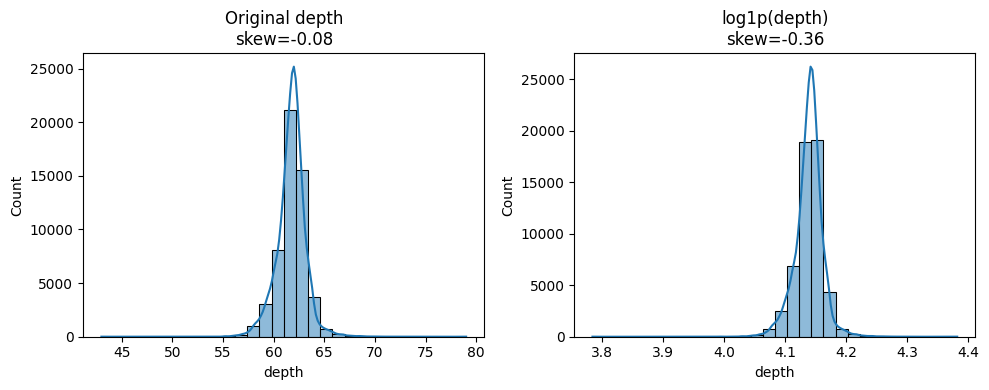

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(depth_original, bins=30, kde=True, ax=axes[0])
axes[0].set_title(f'Original depth\nskew={depth_original.skew():.2f}')

sns.histplot(depth_log, bins=30, kde=True, ax=axes[1])
axes[1].set_title(f'log1p(depth)\nskew={pd.Series(depth_log).skew():.2f}')

plt.tight_layout()
plt.show()

The original depth variable has a skewness of -0.08, indicating an approximately symmetric distribution. Both the histogram and Q-Q plot show that the original data are already close to normally distributed. After applying log1p, the skewness increased to -0.36 and the tails deviated further from the reference line in the Q-Q plot. This suggests that the transformation moved the distribution away from normality. Therefore, applying log1p to an already near-normal variable is unnecessary and may even worsen its distributional properties.

<a id="toc-exercise-4-3"></a>
### Exercise 4


In [51]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import PowerTransformer

class SkewnessSelector(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.5):
        self.threshold = threshold

    def fit(self, X, y=None):

        X = pd.DataFrame(X).copy()

        self.columns_ = X.columns

        self.skewness_ = X.skew()

        self.transform_cols_ = [
            col for col in self.columns_
            if abs(self.skewness_[col]) > self.threshold
        ]

        self.pt_ = PowerTransformer(method='yeo-johnson')

        if len(self.transform_cols_) > 0:
            self.pt_.fit(X[self.transform_cols_])

        return self

    def transform(self, X):

        X = pd.DataFrame(X).copy()

        if len(self.transform_cols_) > 0:
            X[self.transform_cols_] = self.pt_.transform(
                X[self.transform_cols_]
            )

        return X

In [52]:
X_test = diamonds[['carat', 'depth', 'table', 'price']]

selector = SkewnessSelector(threshold=0.5)

X_trans = selector.fit_transform(X_test)

print('Columns selected for transformation:')
print(selector.transform_cols_)

print('\nSkewness before:')
print(X_test.skew())

print('\nSkewness after:')
print(X_trans.skew())

Columns selected for transformation:
['carat', 'table', 'price']

Skewness before:
carat    1.116646
depth   -0.082294
table    0.796896
price    1.618395
dtype: float64

Skewness after:
carat    0.117887
depth   -0.082294
table   -0.037098
price    0.025726
dtype: float64


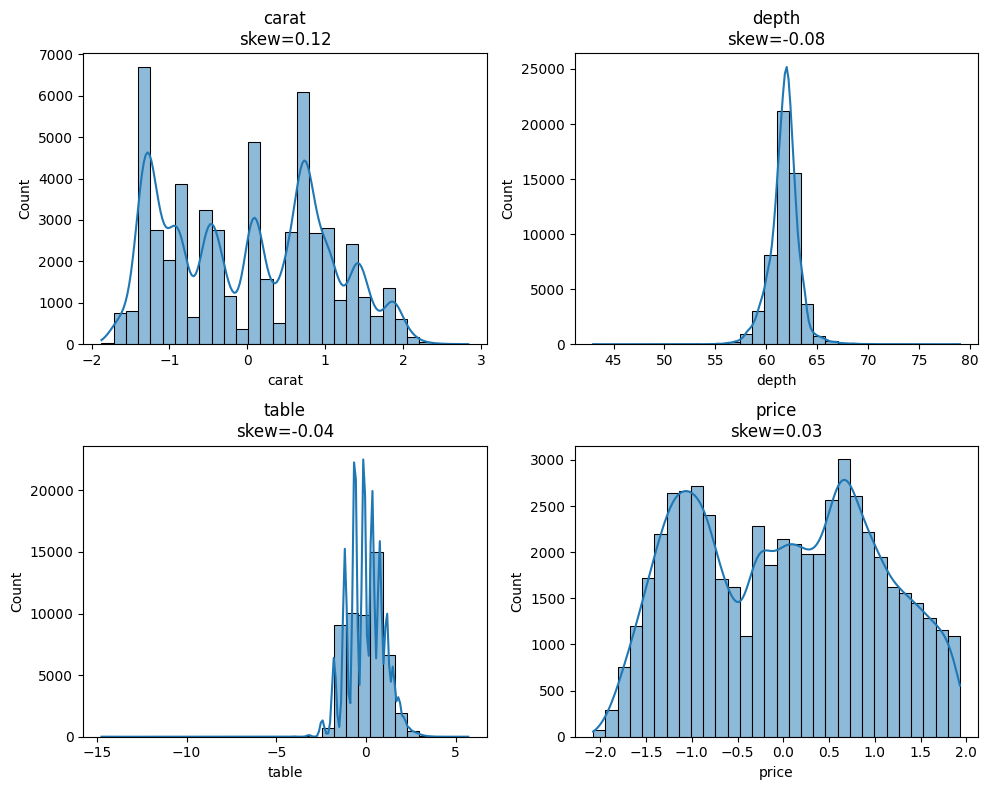

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(10,8))

for ax, col in zip(axes.ravel(), X_test.columns):
    sns.histplot(X_trans[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'{col}\nskew={X_trans[col].skew():.2f}')

plt.tight_layout()
plt.show()

The SkewnessSelector automatically identifies features with absolute skewness greater than 0.5 and applies a Yeo-Johnson transformation only to those variables. As a result, carat, table, and price were transformed, while depth remained unchanged. The skewness values of carat, table, and price were reduced from 1.12, 0.80, and 1.62 to 0.12, -0.04, and 0.03, respectively, making the distributions much more symmetric. This demonstrates that the custom transformer successfully detects highly skewed features and improves their distribution while leaving already well-behaved variables untouched.

<a id="toc-3-2-sklearn-pipline"></a>
## 3.2. Sklearn Pipline

<a id="toc-exercise-1-4"></a>
### Exercise 1

In [54]:
import numpy as np
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

In [55]:
# Prepare data

titanic = sns.load_dataset("titanic")

features = ["pclass", "age", "fare"]
X = titanic[features]
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Columns used in X_train:")
print(X_train.columns.tolist())

Columns used in X_train:
['pclass', 'age', 'fare']


In [56]:
# Define custom LogTransformer

class LogTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.log1p(X)

In [57]:
# Baseline ColumnTransformer: without log-transforming fare

baseline_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age", "fare"]),

    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), ["pclass"])
])

baseline_pipe = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=7))
])

baseline_scores = cross_val_score(
    baseline_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Baseline CV accuracy:")
print(f"Mean = {baseline_scores.mean():.4f}")
print(f"Std  = {baseline_scores.std():.4f}")

Baseline CV accuracy:
Mean = 0.7036
Std  = 0.0219


In [58]:
# ColumnTransformer with log1p applied only to fare

log_preprocessor = ColumnTransformer([
    ("age", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age"]),

    ("fare_log", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log", LogTransformer()),
        ("scaler", StandardScaler())
    ]), ["fare"]),

    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), ["pclass"])
])

log_pipe = Pipeline([
    ("preprocessor", log_preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=7))
])

log_scores = cross_val_score(
    log_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Log-transformed fare CV accuracy:")
print(f"Mean = {log_scores.mean():.4f}")
print(f"Std  = {log_scores.std():.4f}")

Log-transformed fare CV accuracy:
Mean = 0.7163
Std  = 0.0259


In [59]:
# Compare results

difference = log_scores.mean() - baseline_scores.mean()
threshold = 1e-4

print("Comparison:")
print(f"Baseline mean accuracy = {baseline_scores.mean():.6f}")
print(f"Log-fare mean accuracy = {log_scores.mean():.6f}")
print(f"Difference             = {difference:+.6f}")

if difference > threshold:
    print("The log transformation improves cross-validated accuracy.")
elif difference < -threshold:
    print("The log transformation decreases cross-validated accuracy.")
else:
    print("The log transformation has almost no effect on cross-validated accuracy.")

Comparison:
Baseline mean accuracy = 0.703625
Log-fare mean accuracy = 0.716271
Difference             = +0.012647
The log transformation improves cross-validated accuracy.


<a id="toc-exercise-2-4"></a>
### Exercise 2

In [60]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

In [61]:
# Prepare data
titanic = sns.load_dataset("titanic")

features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "deck"]

X = titanic[features]
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Columns used in X_train:")
print(X_train.columns.tolist())

print("Missing percentage of deck:")
print(f"{X_train['deck'].isna().mean() * 100:.2f}%")

Columns used in X_train:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'deck']
Missing percentage of deck:
77.67%


In [62]:
# Baseline pipeline: without deck

baseline_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age", "fare", "sibsp", "parch"]),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["sex", "embarked"]),

    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), ["pclass"])
])

baseline_pipe = Pipeline([
    ("preprocessor", baseline_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
])

baseline_scores = cross_val_score(baseline_pipe, X_train, y_train, cv=cv, scoring="accuracy")

print("Baseline CV accuracy:")
print(f"Mean = {baseline_scores.mean():.4f}")
print(f"Std  = {baseline_scores.std():.4f}")

Baseline CV accuracy:
Mean = 0.8132
Std  = 0.0191


In [63]:
# Extended pipeline: include deck and handle missingness inside the Pipeline

extended_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age", "fare", "sibsp", "parch"]),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["sex", "embarked"]),

    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), ["pclass"]),

    ("deck", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["deck"])
])

extended_pipe = Pipeline([
    ("preprocessor", extended_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
])

extended_scores = cross_val_score(extended_pipe, X_train, y_train, cv=cv, scoring="accuracy")

print("Extended pipeline with deck CV accuracy:")
print(f"Mean = {extended_scores.mean():.4f}")
print(f"Std  = {extended_scores.std():.4f}")

Extended pipeline with deck CV accuracy:
Mean = 0.8146
Std  = 0.0245


In [64]:
# Compare results
difference = extended_scores.mean() - baseline_scores.mean()

print("Comparison:")
print(f"Baseline mean accuracy  = {baseline_scores.mean():.4f}")
print(f"With deck mean accuracy = {extended_scores.mean():.4f}")
print(f"Difference              = {difference:+.4f}")


Comparison:
Baseline mean accuracy  = 0.8132
With deck mean accuracy = 0.8146
Difference              = +0.0014


The extended pipeline included the deck column as an additional categorical feature. Since deck had a high missing rate of 77.67%, missing values were handled inside the pipeline by replacing them with "Unknown" before one-hot encoding. The baseline pipeline achieved a mean cross-validated accuracy of 0.8132, while the pipeline with deck achieved 0.8146. The improvement was only 0.0014, so adding deck produced a very slight improvement but had limited impact on overall model performance.

<a id="toc-exercise-3-4"></a>
### Exercise 3

In [65]:
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

In [66]:
# Prepare data

titanic = sns.load_dataset("titanic")

features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = titanic[features]
y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Columns used in X_train:")
print(X_train.columns.tolist())

Columns used in X_train:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


In [67]:
# Build ColumnTransformer
preprocessor = ColumnTransformer([
    ("age", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["age"]),

    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), ["fare", "sibsp", "parch"]),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), ["sex", "embarked"]),

    ("ord", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), ["pclass"])
])

In [68]:
# Build full pipeline

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])

In [69]:
# Define parameter grid using Pipeline parameter notation

param_grid = {
    "preprocessor__age__imputer__strategy": ["median", "most_frequent"],
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 8, None],
    "model__min_samples_split": [2, 5]
}

In [70]:
# Run GridSearchCV

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validated accuracy:")
print(f"{grid_search.best_score_:.4f}")

Best parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200, 'preprocessor__age__imputer__strategy': 'median'}

Best cross-validated accuracy:
0.8244


In [71]:
# Evaluate the best model on the test set

test_accuracy = grid_search.score(X_test, y_test)

print("Test accuracy of the best model:")
print(f"{test_accuracy:.4f}")

Test accuracy of the best model:
0.8101


<a id="toc-exercise-4-4"></a>
### Exercise 4

In [72]:
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

In [73]:
# Prepare numeric data

titanic = sns.load_dataset("titanic")

X = titanic[["age", "fare", "sibsp", "parch"]].copy()
X["fare_squared"] = X["fare"] ** 2

y = titanic["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

print("Columns used in X_train:")
print(X_train.columns.tolist())

Columns used in X_train:
['age', 'fare', 'sibsp', 'parch', 'fare_squared']


In [74]:
# Correct approach: imputer and scaler inside the Pipeline

correct_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

correct_scores = cross_val_score(
    correct_pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Correct Pipeline CV accuracy:")
print(f"Mean = {correct_scores.mean():.4f}")
print(f"Std  = {correct_scores.std():.4f}")

Correct Pipeline CV accuracy:
Mean = 0.6826
Std  = 0.0224


In [75]:
# Wrong approach: fit imputer and scaler before cross-validation

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train)
X_train_scaled = scaler.fit_transform(X_train_imputed)

leaky_model = KNeighborsClassifier(n_neighbors=5)

leaky_scores = cross_val_score(
    leaky_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Leaky CV accuracy:")
print(f"Mean = {leaky_scores.mean():.4f}")
print(f"Std  = {leaky_scores.std():.4f}")

Leaky CV accuracy:
Mean = 0.6882
Std  = 0.0317


In [76]:
# Compare results
difference = leaky_scores.mean() - correct_scores.mean()

print("Comparison:")
print(f"Correct Pipeline mean accuracy = {correct_scores.mean():.4f}")
print(f"Leaky preprocessing accuracy   = {leaky_scores.mean():.4f}")
print(f"Difference                     = {difference:+.4f}")


Comparison:
Correct Pipeline mean accuracy = 0.6826
Leaky preprocessing accuracy   = 0.6882
Difference                     = +0.0056


The correct pipeline achieved a mean cross-validated accuracy of 0.6826, while the leaky preprocessing approach achieved 0.6882. The difference was +0.0056, showing that fitting the imputer and scaler before cross-validation inflated the CV score. This happens because the preprocessing parameters were estimated from the full training set, so information from the validation folds leaked into the training process.